# Lab 1 — Part 1: N-Gram Language Model

1. Data preprocessing
2. Unigram baseline
3. Extending to bigrams, trigrams, ... N-grams
4. Laplace (add-one) smoothing
5. Text generation
6. Perplexity evaluation for n = 1 … 10

**Data:** train on `shakespeare-caesar` + `shakespeare-macbeth`, evaluate on `shakespeare-hamlet` .

## Setup

We import the libraries and download the NLTK resources we need (the Gutenberg corpus, the sentence tokenizer, and the stopword list for the optional experiment).

In [1]:
import re, math, random
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
import nltk

for pkg in ["gutenberg", "punkt", "punkt_tab", "stopwords"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import gutenberg, stopwords
from nltk.tokenize import sent_tokenize

TRAIN_FILES = ["shakespeare-caesar.txt", "shakespeare-macbeth.txt"]
TEST_FILES  = ["shakespeare-hamlet.txt"]

SEED = 42
random.seed(SEED); np.random.seed(SEED)

## Data Preprocessing

**What we do and why**

| Step | Why |
|---|---|
| **Sentence splitting** (`sent_tokenize`) | An N-gram model predicts a word from the previous *n-1* words. We split the text into sentences so we can mark where sentences start and end with `<s>` and `</s>` — otherwise the model could never learn how sentences begin/end, and context would leak across sentence boundaries. |
| **Lowercasing** | `The` and `the` should be the same word; otherwise counts get split across variants and the data becomes sparser. |
| **Tokenization + punctuation removal** | A single regex extracts word tokens (letters/digits, with an optional inner apostrophe so `o'er`, `don't` stay as one word) — everything else (punctuation, brackets, special characters) is dropped. |
| **Stopword removal (optional)** | Controlled by a flag. We keep it **off** for language modelling: stopwords (`the`, `of`, `to` …) are a large part of real text and carry the grammatical structure the model is supposed to learn. Removing them would make the text unnatural and the perplexities not comparable with a "normal" LM. We still provide the switch so you can run the experiment. |

Special tokens used later:
- `<s>` — start-of-sentence padding (n-1 copies are prepended for an n-gram model)
- `</s>` — end-of-sentence token (lets the model learn when to stop)
- `<UNK>` — any word never seen in training (needed because Hamlet contains words that Caesar/Macbeth don't)

In [2]:
REMOVE_STOPWORDS = False          # optional step 
STOP = set(stopwords.words("english"))   # optional step

WORD_REGEX = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")   

def preprocess(txt_file, remove_stopwords=REMOVE_STOPWORDS):
    sentences = []
    for fid in txt_file:
        raw = gutenberg.raw(fid)
        for sent in sent_tokenize(raw):
            tokens = WORD_REGEX.findall(sent.lower())          # lowercase + tokenize + drop punctuation
            if remove_stopwords:
                tokens = [t for t in tokens if t not in STOP]
            if tokens:
                sentences.append(tokens)
    return sentences

train_sents = preprocess(TRAIN_FILES)
test_sents  = preprocess(TEST_FILES)

n_train = sum(map(len, train_sents))
n_test = sum(map(len, test_sents))
print(f"Train: {len(train_sents):,} sentences, {n_train:,} tokens, {len(set(w for s in train_sents for w in s)):,} unique words")
print(f"Test : {len(test_sents):,} sentences, {n_test:,} tokens, {len(set(w for s in test_sents for w in s)):,} unique words")
print("\nExample sentence:", train_sents[10])

Train: 3,057 sentences, 38,365 tokens, 5,218 unique words
Test : 2,355 sentences, 29,699 tokens, 4,813 unique words

Example sentence: ['what', 'dost', 'thou', 'with', 'thy', 'best', 'apparrell', 'on']


In [3]:
train_vocab_words = {w for s in train_sents for w in s}
oov_tokens = sum(1 for s in test_sents for w in s if w not in train_vocab_words)
print(f"Out-of-vocabulary test tokens: {oov_tokens:,} / {n_test:,}  ({100*oov_tokens/n_test:.1f}%)")

Out-of-vocabulary test tokens: 4,520 / 29,699  (15.2%)


## 2. Unigram Model (baseline)

A **unigram** model assumes every word is independent of the others:

$$P(w_1,\dots,w_m)=\prod_{i=1}^{m}P(w_i),\qquad P(w)=\frac{C(w)}{N}$$

where $C(w)$ is the number of times $w$ appears in the training data and $N$ is the total number of training tokens (including `</s>`).

In [4]:
def add_sentence_markers(tokens, n):
    return ["<s>"] * (n - 1) + tokens + ["</s>"]

unigram_counts = Counter()
for s in train_sents:
    unigram_counts.update(add_sentence_markers(s, 1))
N = sum(unigram_counts.values())

def unigram_prob(w):
    return unigram_counts[w] / N          # No smoothing yet

print("Total tokens N =", N, "| vocabulary size =", len(unigram_counts))
print("Most common:", [(w, round(unigram_prob(w), 4)) for w, _ in unigram_counts.most_common(8)])

Total tokens N = 41422 | vocabulary size = 5219
Most common: [('</s>', 0.0738), ('the', 0.0296), ('and', 0.0283), ('i', 0.0208), ('to', 0.02), ('of', 0.0167), ('you', 0.0143), ('that', 0.0124)]


## 3. Extending to Bigrams, Trigrams, … N-grams

An **n-gram** model conditions each word only on the previous $n-1$ words (the Markov assumption):

$$P(w_i\mid w_1,\dots,w_{i-1})\approx P(w_i\mid w_{i-n+1},\dots,w_{i-1})$$

estimated by counting (maximum likelihood):

$$P(w_i\mid w_{i-n+1}^{i-1})=\frac{C(w_{i-n+1}^{i})}{C(w_{i-n+1}^{i-1})}$$

- `n = 1` → unigram, `n = 2` → bigram (uses 1 previous word), `n = 3` → trigram (uses 2 previous words), …
- To give the first words of a sentence a full context, we pad with `n-1` copies of `<s>`.
- We store **two** count tables: counts of full n-grams, and counts of their (n-1)-word *contexts*. The class below works for **any** `n` (so we can go up to 10), and it already supports Laplace smoothing through the parameter `k` (section 4) — with `k=0` it is the plain MLE model.

We also build the vocabulary here: training words that occur at least `min_count=2` times, plus `</s>` and `<UNK>`. **Words that appear only once in training are replaced by `<UNK>`**, and at test time any word outside the vocabulary is also mapped to `<UNK>`. This matters: if `<UNK>` were never seen in training, the model would assign it almost zero probability and every unknown Hamlet word (about 15% of the test tokens) would be punished far too hard. Training on `<UNK>` lets the model learn a realistic probability for 'some word I don't know'.

In [14]:
class NGramLM:
    def __init__(self, n, k=1.0, min_count=2):
        self.n, self.k, self.min_count = n, k, min_count
        self.ngram_counts   = Counter()                 # C(context + word)
        self.context_counts = Counter()                 # C(context)
        self.next_words   = defaultdict(Counter)        # context -> Counter(word)  (used for generation)
        self.vocab = set()

    # training
    def fit(self, sentences):
        freq = Counter(w for s in sentences for w in s)
        self.vocab = {w for w, c in freq.items() if c >= self.min_count} | {"</s>", "<UNK>"} 
        for s in sentences:
            toks = add_sentence_markers(self._map_unk(s), self.n)   
            for i in range(self.n - 1, len(toks)):
                context = tuple(toks[i - self.n + 1 : i])
                word = toks[i]
                self.ngram_counts[context + (word,)] += 1
                self.context_counts[context] += 1
                self.next_words[context][word] += 1
        self.V = len(self.vocab)
        return self

    def _map_unk(self, tokens):
        return [w if w in self.vocab else "<UNK>" for w in tokens]

    # probability of a single word given a context
    def prob(self, context, word):
        context = tuple(context)
        num = self.ngram_counts[context + (word,)] + self.k
        den = self.context_counts[context] + self.k * self.V
        return num / den if den > 0 else 0.0

    # log-probability of a whole sentence
    def sentence_logprob(self, tokens):
        toks = add_sentence_markers(self._map_unk(tokens), self.n)
        logp, count = 0.0, 0
        for i in range(self.n - 1, len(toks)):
            p = self.prob(toks[i - self.n + 1 : i], toks[i])
            if p == 0.0:
                return float("-inf"), count + 1
            logp += math.log(p); count += 1
        return logp, count

## 4. Laplace Smoothing

**The problem.** With MLE, any n-gram that never occurred in training gets probability **0**. One such n-gram makes the probability of the whole test sentence 0, and the perplexity infinite. This gets *much* worse as $n$ grows, because long n-grams almost never repeat.

**Laplace (add-one) smoothing.** Pretend every possible n-gram was seen one extra time:

$$P_{\text{Laplace}}(w_i\mid \text{ctx})=\frac{C(\text{ctx},w_i)+1}{C(\text{ctx})+V}$$


In [15]:
trigram_mle  = NGramLM(3, k=0).fit(train_sents)
trigram_lap  = NGramLM(3, k=1).fit(train_sents)

sample = next(x for x in test_sents if 8 <= len(x) <= 12)
print("Hamlet sentence:", " ".join(sample))
print("log P  (no smoothing):", trigram_mle.sentence_logprob(sample)[0])
print("log P  (Laplace)     :", round(trigram_lap.sentence_logprob(sample)[0], 2))

Hamlet sentence: the tragedie of hamlet by william shakespeare 1599 actus primus
log P  (no smoothing): -inf
log P  (Laplace)     : -71.73


## 5. Generation Function

To generate text from an n-gram model we **sample** one word at a time:

1. Start with the context `<s> … <s>` (n-1 start tokens), or with a user-given prompt.
2. Look at the current context (last n-1 words), get the probability distribution $P(w\mid\text{ctx})$ over the vocabulary.
3. **Sample** the next word from that distribution (using `numpy`'s random choice).
4. Append it to the text, slide the context window, and repeat until `</s>` is produced or the length limit is reached.

Two modes (parameter `smoothed`):
- `smoothed=False` (default) — sample only among the words **actually observed** after the context. If the context was never seen, we **back off** to a shorter context. This produces the most readable text because the model only reuses real continuations.
- `smoothed=True` — sample from the full **Laplace-smoothed** distribution over the whole vocabulary. This is the "pure" model, but for high $n$ most contexts are unseen, so the distribution is almost uniform and the output turns into random words (a nice demonstration of why Laplace is a poor smoother for large $n$).

The temperature-free sampling means each run gives different text; we fix the seed for reproducibility.

In [16]:
def _sample_from_counts(counter, rng):
    words = list(counter.keys())
    probs = np.array([counter[w] for w in words], dtype=float)
    return words[rng.choice(len(words), p=probs / probs.sum())]

def generate(model, prompt="", max_words=30, smoothed=False, seed=None):
    rng = np.random.default_rng(seed)
    n = model.n
    words = model._map_unk(WORD_REGEX.findall(prompt.lower())) if prompt else []
    history = ["<s>"] * (n - 1) + words
    vocab_list = sorted(model.vocab)

    out = list(words)
    for _ in range(max_words):
        context = tuple(history[len(history) - (n - 1):]) if n > 1 else ()

        if smoothed:
            probs = np.array([model.prob(context, w) for w in vocab_list])
            nxt = vocab_list[rng.choice(len(vocab_list), p=probs / probs.sum())]
        else:
            ctx = context
            while ctx and not model.next_words.get(ctx):
                ctx = ctx[1:]
            nxt = _sample_from_counts(model.next_words[ctx], rng)

        if nxt == "</s>":
            break
        out.append(nxt); history.append(nxt)
    return " ".join(out)

lm_gen = {n: NGramLM(n, k=1).fit(train_sents) for n in (1, 2, 3, 4)}

for n in (1, 2, 3, 4):
    print(f"--- n = {n}")
    for i in range(2):
        print("  ", generate(lm_gen[n], max_words=25, seed=100 + i))
print()
print("--- trigram with a prompt: 'the king' ---")
print("  ", generate(lm_gen[3], prompt="the king", max_words=25, seed=7))
print("\n--- trigram, FULL Laplace-smoothed distribution ---")
print("  ", generate(lm_gen[3], max_words=25, smoothed=True, seed=1))

--- n = 1
   cymber so not of fellowes so night hot bru
   compell'd i crowne finde being tent rise i play and execution was men of thriue for me i shall in see but <UNK> is soundly
--- n = 2
   call timely on your sword there's nothing can entreat a walking crowne to our loue brutus should i thanke you marke that her giue thee
   goes our time
--- n = 3
   call em let me finde him fortune and more terrible and caesar shall not liue looke with a new father wife
   goes the world brut
--- n = 4
   call em let me see is not the leafe turn'd downe where i left <UNK>
   goes the king hence to day

--- trigram with a prompt: 'the king' ---
   the king hence to day bru

--- trigram, FULL Laplace-smoothed distribution ---
   liue wel choose wee fleance humble strong holds mothers amisse shewes mile found sorrow fight kingdomes cauldron highnesse decree english shape faint lightning wonders whither


**Reading the output.** The unigram text is a bag of random frequent words with no structure. Bigrams give locally plausible word pairs; trigrams and 4-grams start copying whole phrases from the plays (the data is small, so higher-order models memorize — and short outputs like `goes the king hence to day` appear because the model reached `</s>` early). Tokens such as `bru` or `macd` are speaker abbreviations from the script. The fully-smoothed trigram generates mostly random vocabulary words because most trigram contexts are unseen and Laplace then spreads probability almost uniformly.

## 6. Evaluation: Perplexity

**Perplexity** measures how "surprised" the model is by unseen text — lower is better. For a test set with $N$ predicted tokens:

$$\text{PP}=\exp\!\Big(-\frac1N\sum_{i=1}^{N}\log P(w_i\mid \text{context}_i)\Big)$$

It is the inverse probability of the test set, normalised per word. Intuitively, a perplexity of 200 means the model is as uncertain as if it had to choose uniformly among 200 words at every step.

Implementation details:
- We sum **log**-probabilities (multiplying thousands of small probabilities would underflow to 0).
- Every sentence is padded with `<s>` / `</s>`; `</s>` counts as a predicted token, `<s>` does not.
- Test words not in the training vocabulary are mapped to `<UNK>`.
- Models are trained on **Caesar + Macbeth** and evaluated on **Hamlet**.
- Without smoothing, one unseen n-gram gives $P=0$ → $\text{PP}=\infty$; we show this too.

Perplexity is the standard metric used to measure how well a language model predicts text. A lower perplexity score means the model is less "confused" by the test data and is better at predicting the next word.
Conceptually, if a model has a perplexity of 100, it means that when trying to predict the next word, it is mathematically as confused as if it had to guess equally among 100 different words

In [17]:
def perplexity(model, sentences):
    total_logp, total_tokens = 0.0, 0
    for s in sentences:
        lp, cnt = model.sentence_logprob(s)
        if lp == float("-inf"):
            return float("inf")
        total_logp += lp; total_tokens += cnt
    return math.exp(-total_logp / total_tokens)

results = []
for n in range(1, 11):
    train_pp_model = NGramLM(n, k=1).fit(train_sents)           # Laplace
    mle_model      = NGramLM(n, k=0).fit(train_sents)           # no smoothing
    results.append((n,
                    perplexity(train_pp_model, test_sents),     # Hamlet, Laplace
                    perplexity(mle_model, test_sents),          # Hamlet, MLE
                    ))   # training set, Laplace

print(f"{'n':>2} | {'Hamlet PP (Laplace)':>20} | {'Hamlet PP (no smoothing)':>25}")
print("-" * 76)
for n, pp_l, pp_m in results:
    print(f"{n:>2} | {pp_l:>20.1f} | {pp_m:>25} ")

 n |  Hamlet PP (Laplace) |  Hamlet PP (no smoothing)
----------------------------------------------------------------------------
 1 |                186.5 |        182.87198993458014 
 2 |                483.4 |                       inf 
 3 |               1446.8 |                       inf 
 4 |               1815.7 |                       inf 
 5 |               1867.2 |                       inf 
 6 |               1871.7 |                       inf 
 7 |               1872.3 |                       inf 
 8 |               1872.8 |                       inf 
 9 |               1873.2 |                       inf 
10 |               1873.2 |                       inf 


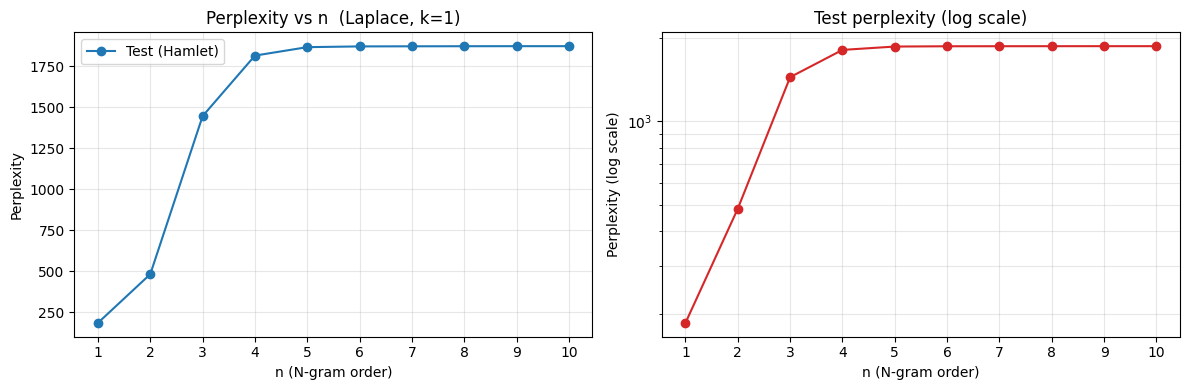

Best test perplexity: n=1  (PP = 186.5)


In [9]:
ns   = [r[0] for r in results]
ppL  = [r[1] for r in results]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ns, ppL, "o-", label="Test (Hamlet)")
ax[0].set_xlabel("n (N-gram order)"); ax[0].set_ylabel("Perplexity"); ax[0].set_xticks(ns)
ax[0].set_title("Perplexity vs n  (Laplace, k=1)"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(ns, ppL, "o-", color="tab:red")
ax[1].set_yscale("log"); ax[1].set_xlabel("n (N-gram order)"); ax[1].set_ylabel("Perplexity (log scale)")
ax[1].set_xticks(ns); ax[1].set_title("Test perplexity (log scale)"); ax[1].grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

best = min(results, key=lambda r: r[1])
print(f"Best test perplexity: n={best[0]}  (PP = {best[1]:,.1f})")

### Why does perplexity behave like this?

**Results (train: Caesar + Macbeth, test: Hamlet, Laplace k=1):** perplexity is about **187** for n=1, **483** for n=2, **1,447** for n=3, **1,816** for n=4, and it flattens out at roughly **1,870** from n=5 up to n=10. So in this experiment **more context made the model worse, not better** — the unigram baseline wins. This is not a bug; there are three reasons:

1. **Data sparsity.** The training set is tiny (about 38k tokens, vocabulary about 2.4k words). Most bigrams occur once, and most trigrams, 4-grams, ... of Hamlet never appeared in Caesar/Macbeth. The longer the n-gram, the more test contexts are completely unseen.
2. **Laplace gives too much mass to unseen events.** For a context seen only a few times, the denominator is $C(\text{ctx})+V$ with $V\approx 2{,}357$, so the words that really followed that context keep only a tiny share of the probability and almost all of the mass is spread over thousands of words that never followed it. For an unseen context the model is simply uniform, $P\approx 1/V$.
3. **The plateau for n ≥ 5.** At this point practically every Hamlet context is unseen (except the `<s> … <s>` start contexts), so the model behaves like a uniform distribution over the vocabulary and perplexity stops changing. It stays below $V$ only because of those start-of-sentence contexts.

**Other observations**
- **Without smoothing**, perplexity is **infinite for every n ≥ 2** (only the unigram stays finite, 182.9, because `<UNK>` absorbs unknown words). A single unseen n-gram makes the test probability zero — this is exactly the role of smoothing: it gives the model a way to generalize to unseen sequences, at the cost of some accuracy on seen ones.
- **Train vs. test:** for n ≥ 2 the training perplexity is lower than the test perplexity, and the gap grows with n — the model memorizes the training plays (which also explains the copied phrases in the generated text). For n = 1 the training number is higher only because rare training words (count 2–3) are expensive for a unigram model, whereas many Hamlet tokens fall in the cheap `<UNK>` class.
- **Section 7** shows that a smaller smoothing constant helps the higher-order models a lot (bigram: 483 → 240 with k=0.05; trigram: 1,447 → 826 with k=0.01), but on a corpus this small they still do not beat the unigram. Better fixes are more training data, or smarter smoothing such as **interpolation / backoff / Kneser–Ney**, which combine lower-order and higher-order estimates instead of spreading mass uniformly.
- Perplexities are only comparable between models that use the **same preprocessing and vocabulary** (here: lowercase, no punctuation, `min_count=2`, `<UNK>`, stopwords kept).